## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [19]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [20]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('audio/reference.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: audio\reference.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

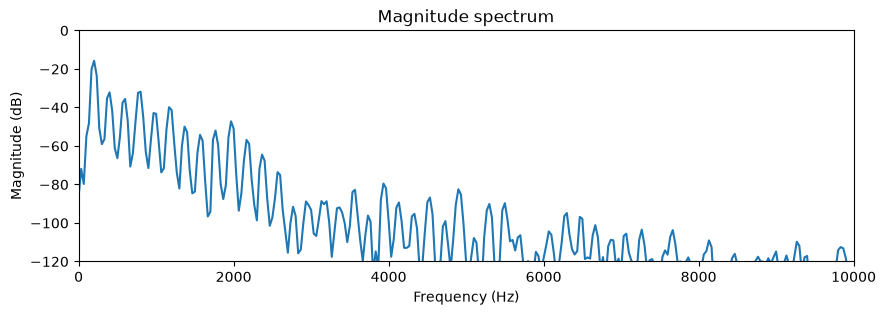

In [21]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - Si en la f = 2000 vemos 10 picos anteriores, 2000/10 = 200Hz. La frecuencia fundamental es f0= 200hz. El 2000 se encuentra en el armonico n = 10, la f=4000 en el armonico n = 20...

2. Do you see a fundamental frequency and its harmonics? How did you identify them?
   - Si, cada pico corresponde a u harmonico. La frecuencia 400 corresponde a n=2 , 600 n=3... 

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - La señal saldria "desplazada" hacia un costado. 

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

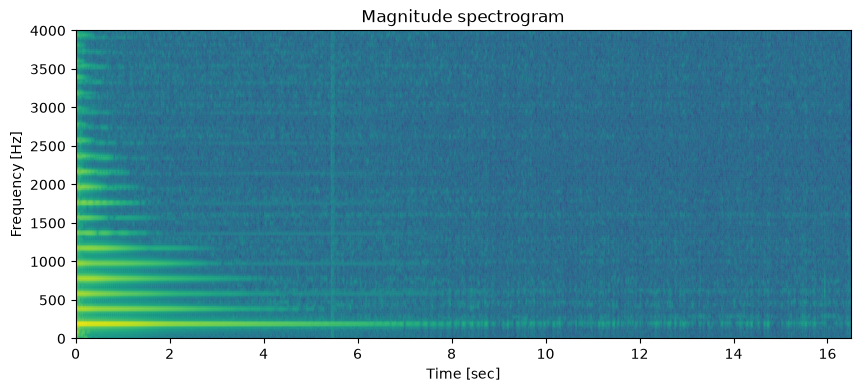

In [22]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   Las frecuencias que aparecen en la mayoria del sonido, son entre 100 i 1200 hz. La mayoritaria, la que aparece duranto casi todo el sonido es la de 100 hz

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - Estas cambian durante el tiempo. Significa que van perdiendo intensidad o se combinan entre otras. Las bandas mas brillantes son las que tienen mas amplitud. 

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - El espectrograma explica la evolución del sonido mostrando visualmente cómo su energía y sus armónicos pierden intensidad de manera desigual a lo largo del tiempo.

#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

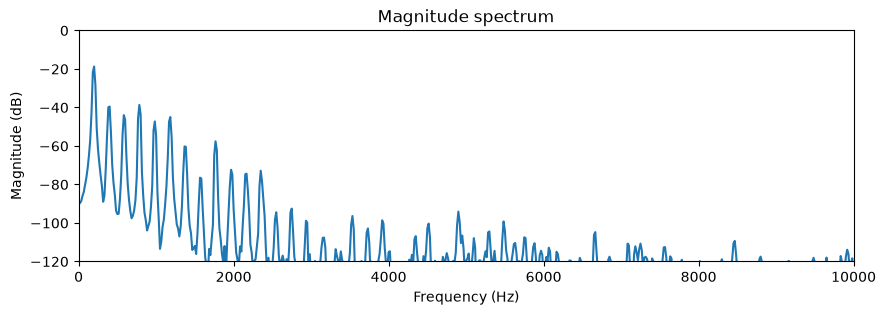

In [23]:
start = int(0.60 * fs)
end = int(0.66 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

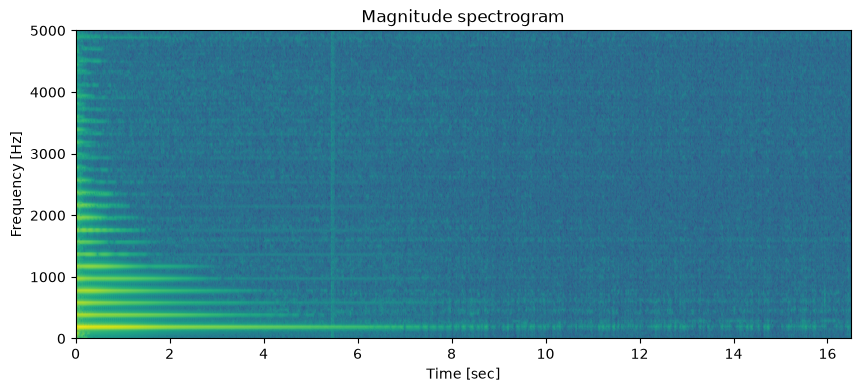

In [24]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 5000])
plt.show()

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [25]:
weights = []  # Fill this list with the measured weights

import numpy as np

# 1. Ponemos laas frecuencias fundamentales f0, i sus respectivos armonicos, f1,f2,f3,f4,f5,f6,f7,f8,f9,f0 = 1000)
weights_db = [100,200,300,400,500,600,700,800,900,1000]
# 2. Convertir de dB a escala lineal (0 a 1)
weights = [10 ** (db / 20) for db in weights_db]

### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [26]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [28]:
from pathlib import Path

#Copiado del Lab1

filepath = None
try:
    # If you have your own file in a cloned repository, uncomment and edit the line below.
    # filepath = Path('./sis1_name/your_file.wav')
    if filepath is None:
        raise FileNotFoundError
    ref, fs = load_audio(filepath)
    print(f'Using audio file: {filepath}')
except FileNotFoundError:
    filepath = Path('audio/PipaChina.wav')
    ref, fs = load_audio(filepath)
    print(f'Using bundled PipaChina audio: {filepath}')

# 1. Parámetros y pesos de la señal sintetizada que use en el LAB2 , pipachinawav, señal artificial2
f0 = 221.6
phi = 2.8
K = 8
A_list = [0.010, 0.113, 1.000, 0.567, 0.466, 0.185, 0.071, 0.022]

# 2. Generación del vector de tiempo a partir de la señal de referencia
t = np.arange(len(ref)) / fs

# 3. Síntesis aditiva mediante el bucle
señalartificial2 = np.zeros_like(t)
for k in range(1, K + 1):
    A = A_list[k - 1]
    señalartificial2 += A * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)

# 4. Normalización
señalartificial2 = 0.34 * señalartificial2 / np.max(np.abs(señalartificial2))

Using bundled PipaChina audio: audio\PipaChina.wav


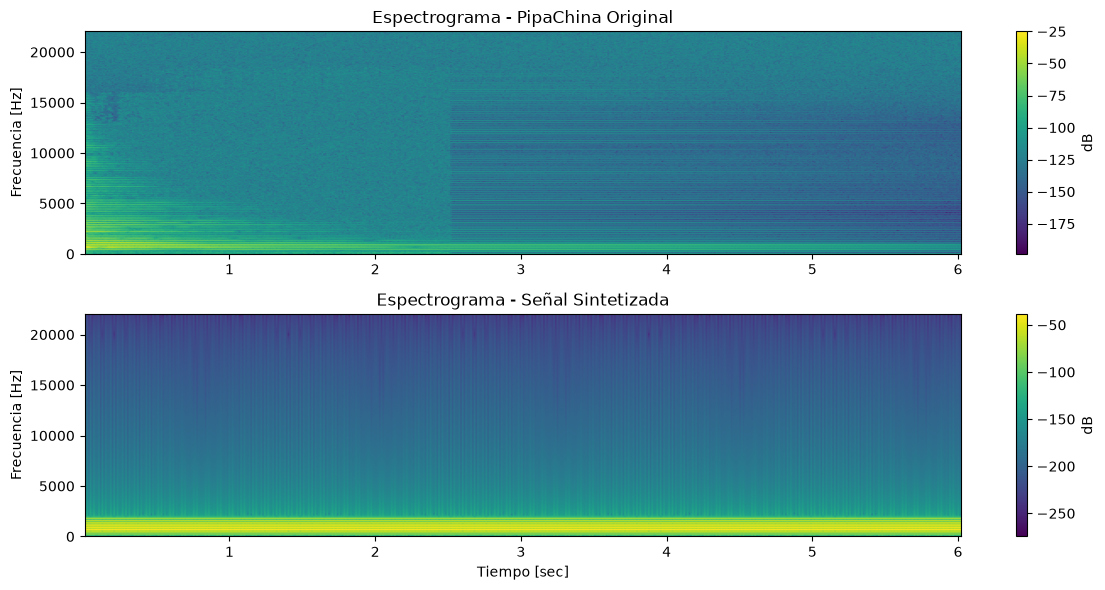

In [29]:
import matplotlib.pyplot as plt

# 1. Gráfica en el dominio del tiempo (Time Domain)
# Si no tienes definidas t_start y t_end, puedes usar por ejemplo t_start=0 y t_end=1
t_start = 0.0
t_end = 1.0

plot_signals(
    [ref, señalartificial2], 
    fs, 
    name=['PipaChina Original', 'Señal Artificial'], 
    t_start=t_start, 
    t_end=t_end
)

# 2. Gráficas de los Espectrogramas (Spectrogram)
plt.figure(figsize=(12, 6))

# Espectrograma de la señal de referencia
plt.subplot(2, 1, 1)
plt.specgram(ref, Fs=fs, NFFT=1024, noverlap=512)
plt.title('Espectrograma - PipaChina Original')
plt.ylabel('Frecuencia [Hz]')
plt.colorbar(label='dB')

# Espectrograma de la señal sintetizada
plt.subplot(2, 1, 2)
plt.specgram(señalartificial2, Fs=fs, NFFT=1024, noverlap=512)
plt.title('Espectrograma - Señal Sintetizada')
plt.xlabel('Tiempo [sec]')
plt.ylabel('Frecuencia [Hz]')
plt.colorbar(label='dB')

plt.tight_layout()
plt.show()

#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - Lo que pasa es que para que coincida TODA la señal artifical , ha faltado calcular las frecuencias de la frequencia envolvente. Los picos de la señal artificial vs la original, cuadran en amplitud inicial y fase, el problema es ese, que no hay una señal o onda envolvente de amplitud. 

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   Bien reproducido: La frecuencia fundamental, los picos armónicos iniciales y la fase coinciden correctamente con la referencia, capturando el timbre básico del instrumento en el instante inicial.   Diferente o faltante: Falta la envolvente de amplitud (el decaimiento del volumen en el tiempo) y el filtrado dinámico de las altas frecuencias (los armónicos agudos deberían apagarse antes que los graves).